In [20]:
from sklearn import svm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.decomposition import PCA
from seaborn import heatmap
import matplotlib.pyplot as plt
import pandas as pd

In [21]:
x = pd.DataFrame(load_breast_cancer()["data"])
x.columns = load_breast_cancer()["feature_names"]
y = load_breast_cancer()["target"]

In [22]:
mms = MinMaxScaler()
mms.fit(x)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](30,)","[ 28.11, 39.28,188.5 ,..., 0.29, 0.66, 0.21]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](30,)","[ 6.98, 9.71,43.79,..., 0. , 0.16, 0.06]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](30,)","[ 21.13, 29.57,144.71,..., 0.29, 0.51, 0.15]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](30,)","[-0.33,-0.33,-0.3 ,..., 0. ,-0.31,-0.36]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,569


In [23]:
x = mms.transform(x)

In [24]:
pca = PCA(2)
pca.fit(x)
transform = pca.transform(x)


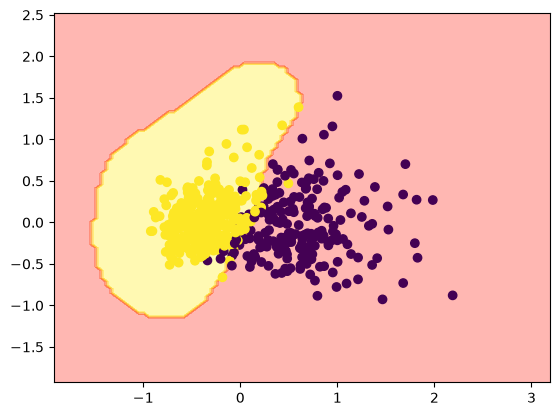

In [ ]:
svc = svm.SVC()
svc.fit(transform,y)


DecisionBoundaryDisplay.from_estimator(svc,transform,response_method="predict",cmap=plt.cm.autumn,alpha=0.3)
plt.scatter(x=transform[:,0],y=transform[:,1],c=y)

plt.show()